# Unwrapping Benchmark

Runtime of each unwrapper from [synthetic_images.ipynb](synthetic_images.ipynb) on its InSAR
earthquake, from small to large images. The scene grows self-similarly at a fixed pixel spacing:
the rupture's length, depth, width and slip scale with the image side $N$, and the tropospheric
delay, whose $k^{-8/3}$ spectrum gives it a standard deviation proportional to $N^{1/3}$, scales
with that. Each pixel is then as hard to unwrap at every size, but there are more of them, and
the phase step across the fault grows with $N$.

Each method runs on the same interferogram. Sizes up to 512 report the best of three runs; a method
that takes longer than `TIME_BUDGET` at one size is not run on larger ones.

In [1]:
import io
import os
import platform
import warnings
from contextlib import contextmanager, redirect_stdout
from importlib.metadata import version
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import snaphu
from skimage.restoration import unwrap_phase

import kamui

# spurs prints a notice about GDAL on import, which it needs only to read files.
with redirect_stdout(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore", SyntaxWarning)
    import spurs

print(platform.platform(), platform.processor() or platform.machine(), f"{os.cpu_count()} CPUs")
for package in (
    "kamui",
    "pylmcf",
    "PyMaxflow",
    "numpy",
    "scipy",
    "scikit-image",
    "snaphu",
    "spurs",
):
    print(f"{package} {version(package)}")

Linux-7.0.0-34-generic-x86_64-with-glibc2.43 x86_64 8 CPUs
kamui 0.3.1.dev3+g15162627c.d20261013
pylmcf 1.3.0
PyMaxflow 1.3.2
numpy 2.5.4
scipy 1.18.1
scikit-image 0.26.0
snaphu 0.4.1
spurs 0.0.2


In [2]:
@contextmanager
def quiet_stdout():
    """Silence SNAPHU, whose executable logs to the process's stdout."""
    saved = os.dup(1)
    with open(os.devnull, "w") as devnull:
        os.dup2(devnull.fileno(), 1)
    try:
        yield
    finally:
        os.dup2(saved, 1)
        os.close(saved)


def power_law_field(shape, beta, rng):
    """Draw a Gaussian random field with a 1/k**beta power spectrum and unit variance."""
    k = np.hypot(np.fft.fftfreq(shape[0])[:, None], np.fft.fftfreq(shape[1])[None, :])
    k[0, 0] = np.inf
    field = np.fft.ifft2(np.fft.fft2(rng.standard_normal(shape)) * k ** (-beta / 2)).real
    return field / field.std()


def multilooked(phase, coherence, looks, rng):
    """Simulate a multilooked interferogram; return its wrapped phase and sample coherence.

    Each output pixel averages looks × looks pairs of circular complex Gaussian samples whose
    correlation is `coherence` and whose phase difference is `phase`.
    """
    rows, cols = phase.shape
    shape = (rows * looks, cols * looks)

    def upsample(a):
        return np.repeat(np.repeat(a, looks, axis=0), looks, axis=1)

    def circular():
        noise = rng.standard_normal(shape) + 1j * rng.standard_normal(shape)
        return (noise / np.sqrt(2)).astype(np.complex64)

    def multilook(a):
        return a.reshape(rows, looks, cols, looks).sum(axis=(1, 3))

    gamma = upsample(coherence).astype(np.float32)
    first = circular()
    rotation = np.exp(-1j * upsample(phase)).astype(np.complex64)
    second = (gamma * first + np.sqrt(1 - gamma**2) * circular()) * rotation
    igram = multilook(first * np.conj(second))
    power = multilook(np.abs(first) ** 2) * multilook(np.abs(second) ** 2)
    return np.angle(igram), np.abs(igram) / np.sqrt(power)


def interferogram(phase, coherence, looks, rng, block=256):
    """Simulate `multilooked` block by block of rows, to bound memory."""
    blocks = [
        multilooked(phase[start : start + block], coherence[start : start + block], looks, rng)
        for start in range(0, len(phase), block)
    ]
    wrapped, sample = zip(*blocks, strict=True)
    return np.concatenate(wrapped), np.concatenate(sample)


def earthquake(n, rng):
    """Simulate the earthquake of synthetic_images.ipynb, scaled from 256 to n pixels a side.

    Returns the true phase, the wrapped phase and the sample coherence.
    """
    scale = n / 256
    yy, xx = np.mgrid[0:n, 0:n]
    atmosphere = 1.5 * scale ** (1 / 3) * power_law_field((n, n), 8 / 3, rng)
    coherence = np.clip(0.6 + 0.2 * power_law_field((n, n), 8 / 3, rng), 0.15, 0.95)
    along = (yy - 73 * scale) / (110 * scale)  # 0 and 1 at the rupture's tips
    slip = 12 * np.pi * scale * np.sin(np.pi * np.clip(along, 0, 1))
    across = xx - 128 * scale + 0.3 * (yy - n / 2)  # distance from the fault trace, roughly
    depth = 15 * scale
    truth = slip / np.pi * np.arctan(depth / np.where(across == 0, 1e-9, across)) + atmosphere
    rupture = (np.abs(across) < 3 * scale) & (along > 0) & (along < 1)
    coherence = np.where(rupture, np.minimum(coherence, 0.2), coherence)
    wrapped, sample = interferogram(truth, coherence, 3, rng)
    return truth, wrapped, sample


def unwrap_snaphu(wrapped, coherence):
    """Unwrap with SNAPHU's deformation cost, given the sample coherence of 3 × 3 looks."""
    igram = np.exp(1j * wrapped).astype(np.complex64)
    with quiet_stdout():
        unwrapped, _ = snaphu.unwrap(igram, coherence.astype(np.float32), nlooks=9, cost="defo")
    return unwrapped


def unwrap_spurs(wrapped):
    """Unwrap with spurs, then snap the result to the nearest congruent phase."""
    smooth = spurs.unwrap(wrapped).astype(float)
    return wrapped + 2 * np.pi * np.round((smooth - wrapped) / (2 * np.pi))


METHODS = {
    "skimage": lambda wrapped, coherence: unwrap_phase(wrapped),
    "SNAPHU": unwrap_snaphu,
    "spurs": lambda wrapped, coherence: unwrap_spurs(wrapped),
    "Kamui LEMON": lambda wrapped, coherence: kamui.unwrap_dimensional(wrapped, solver="lemon"),
    "Kamui LEMON, weighted": lambda wrapped, coherence: kamui.unwrap_dimensional(
        wrapped, weights=np.round(coherence * 100), solver="lemon"
    ),
    "Kamui PUMA, weighted": lambda wrapped, coherence: kamui.unwrap_dimensional(
        wrapped, method="gc", weights=coherence
    ),
}


def wrong_fraction(unwrapped, truth):
    """Return the fraction of pixels off the most common multiple of 2π from `truth`."""
    cycles = np.round((unwrapped - truth) / (2 * np.pi))
    values, counts = np.unique(cycles, return_counts=True)
    return np.mean(cycles != values[counts.argmax()])

## Run

In [3]:
SIZES = [128, 256, 512, 1024, 2048]
TIME_BUDGET = 60  # seconds

seconds = {name: {} for name in METHODS}
wrong = {name: {} for name in METHODS}
rng = np.random.default_rng(0)
for n in SIZES:
    truth, wrapped, coherence = earthquake(n, rng)
    for name, unwrap in METHODS.items():
        previous = [size for size in seconds[name]]
        if previous and seconds[name][previous[-1]] > TIME_BUDGET:
            continue
        runs = []
        for _ in range(3 if n <= 512 else 1):
            start = perf_counter()
            unwrapped = unwrap(wrapped, coherence)
            runs.append(perf_counter() - start)
        seconds[name][n] = min(runs)
        wrong[name][n] = wrong_fraction(unwrapped, truth)
        print(f"{n:>5}  {name:<22} {seconds[name][n]:9.3f} s  {wrong[name][n]:7.2%} wrong")

  128  skimage                    0.003 s    1.17% wrong


  128  SNAPHU                     0.101 s    0.96% wrong
  128  spurs                      0.013 s    1.06% wrong
  128  Kamui LEMON                0.034 s    1.01% wrong


  128  Kamui LEMON, weighted      0.044 s    0.51% wrong


  128  Kamui PUMA, weighted       0.096 s    0.75% wrong
  256  skimage                    0.014 s   49.98% wrong


  256  SNAPHU                     0.650 s   48.54% wrong
  256  spurs                      0.054 s    1.09% wrong


...

 2048  skimage                    2.022 s    2.61% wrong


 2048  SNAPHU                  1102.427 s    3.77% wrong


 2048  spurs                      9.950 s    1.34% wrong


 2048  Kamui LEMON              306.918 s    1.05% wrong


 2048  Kamui LEMON, weighted    379.781 s    1.10% wrong


## Results

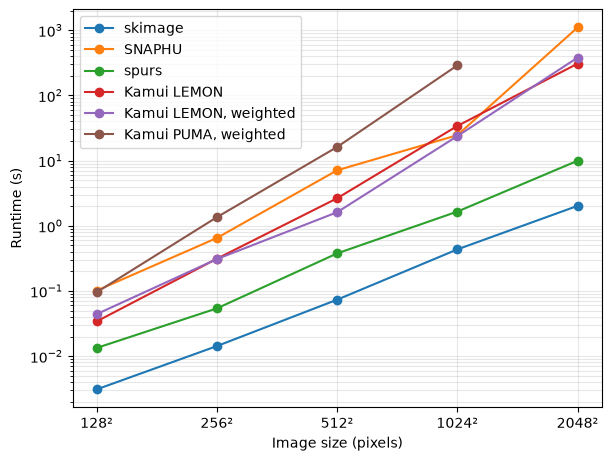

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
for name in METHODS:
    sizes = list(seconds[name])
    ax.plot(sizes, [seconds[name][n] for n in sizes], marker="o", label=name)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(SIZES, [f"{n}²" for n in SIZES])
ax.set_xlabel("Image size (pixels)")
ax.set_ylabel("Runtime (s)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()